## Assignment 7

This assignment encourages you to explore on your own and learn how to use the scikit-learn API for common ML tasks. Some of the material was covered in brief towards the end of the regression lecture.

Read the first 6 sections of [Chapter 5](https://jakevdp.github.io/PythonDataScienceHandbook/05.00-machine-learning.html) of the [Data science handbook](https://jakevdp.github.io/PythonDataScienceHandbook/). These are well written and provide a nice overview of many important concepts. There are also several nice code samples that are worth studying. You will also find the [scikit-learn user guide](https://scikit-learn.org/stable/user_guide.html) very handy to skim or refer.

**Before starting:** place the `data` folder (containing `pendulum.txt`) and `student_performance.csv` in the same directory as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold, validation_curve
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.datasets import make_blobs
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, auc, RocCurveDisplay)

**Loading the pendulum data.** Look at the first rows before using the columns.

In [2]:
data = np.loadtxt("data/pendulum.txt")
print(data[:5])

# Column 0 is the length l (0.10, 0.11, ..., 0.99) and column 1 is the time period t
# (about 0.6 s to 2.1 s, consistent with t = 2*pi*sqrt(l/g)).
length = data[:, 0]
period = data[:, 1]

[[0.1     0.69004]
 [0.11    0.69497]
 [0.12    0.74252]
 [0.13    0.7536 ]
 [0.14    0.83568]]


## Question 1. Train/test split on the pendulum data

Consider the pendulum data provided in the `data/pendulum.txt` file and used in our regression material. Use `sklearn.model_selection.train_test_split` to split the data into 75% training data and 25% test data.  Look at the [sklearn user guide](https://scikit-learn.org/stable/user_guide.html)  to read more about the `train_test_split` functionality. Now use the training data to determine the best fit coefficients using a linear regression (this was done at the end in the regression notebook I shared). Recall that we had a linear model for $l$ vs. $t^2$. Then use the trained model to fit the test data. Calculate the error on the test data using the `model.score` method where `model` is your `LinearRegression` model. Read the documentation of `model.score` to understand what it is computing.

In [3]:
X = length.reshape(-1, 1)      # feature: length
y = period ** 2                # target: square of the time period

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Equation: t^2 = {model.coef_[0]:.4f} l {model.intercept_:+.4f}")
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

# model.score returns the coefficient of determination R^2 of the prediction.
print("Test R^2 score:", model.score(X_test, y_test))

Equation: t^2 = 4.1610 l +0.0598
Coefficient: 4.161043940619855
Intercept: 0.05982915458424243
Test R^2 score: 0.9910376250573891


## Question 2. Using a pandas DataFrame

Convert the pendulum data into a `pandas.DataFrame` object with suitable columns for length `l`,  and the square of the time period, `tsq`. Read the [data as table](https://jakevdp.github.io/PythonDataScienceHandbook/05.02-introducing-scikit-learn.html#Data-as-table) section to see how to use the data frame as your input features matrix and target array. Use this to once again fit a linear model between the length and square of the time period. Note that this is a rather trivial exercise but this should show you how to deal with data frames and use them in scikit-learn.

In [4]:
df_pend = pd.DataFrame({"l": length, "tsq": period ** 2})
print(df_pend.head())

X_df = df_pend[["l"]]          # features matrix (2D, a DataFrame)
y_df = df_pend["tsq"]          # target array (1D, a Series)

model_df = LinearRegression()
model_df.fit(X_df, y_df)

print(f"Equation: tsq = {model_df.coef_[0]:.4f} l {model_df.intercept_:+.4f}")
print("R^2 score:", model_df.score(X_df, y_df))

      l       tsq
0  0.10  0.476155
1  0.11  0.482983
2  0.12  0.551336
3  0.13  0.567913
4  0.14  0.698361
Equation: tsq = 4.1415 l +0.0736
R^2 score: 0.9939316003682754


## Question 3. Cross-validation score

Now just to see how you can compute a cross-validation score, use `sklearn.model_selection.cross_val_score` on the first problem. Use $k=4$ for this, i.e. use the keyword argument `cv=4`. To understand this better, see the [cross-validation user documentation from scikit-learn](https://scikit-learn.org/stable/modules/cross_validation.html).  Note that this should not take you more than 3-4 lines of code after you solve the previous problem.

In [5]:
# Exactly as asked: the first problem's model and data, with cv=4.
scores = cross_val_score(LinearRegression(), X, y, cv=4)
print("Cross-validation scores:", scores)
print("Mean CV score:", scores.mean())

# The data are sorted by length, so unshuffled folds are contiguous blocks of the range.
# Each fold is then partly an extrapolation, so the scores are lower and more spread out.
# Shuffling the folds gives a fairer estimate, close to the single test-set score.
kfold = KFold(n_splits=4, shuffle=True, random_state=42)
scores_shuffled = cross_val_score(LinearRegression(), X, y, cv=kfold)
print("Shuffled CV scores:", scores_shuffled)
print("Mean shuffled CV score:", scores_shuffled.mean())

Cross-validation scores: [0.94132986 0.91703981 0.85374095 0.87361618]
Mean CV score: 0.8964316996716739
Shuffled CV scores: [0.99103763 0.9949857  0.99572302 0.99231691]
Mean shuffled CV score: 0.9935158144134113


## Question 4. Polynomial features

Read the [section on feature engineering](https://jakevdp.github.io/PythonDataScienceHandbook/05.04-feature-engineering.html) from the Python data science handbook. Pay particular attention to the example where the `PolynomialFeatures` preprocessor was highlighted. Use this to redo the linear model for the pendulum data where you use the original feature as $t$ and not the square of the values. Recall, that originally we had taken $t^2$ as the dependent/response variable ($Y$), and the length as the independent/feature variable $x$. Now, reverse this and treat the length as the target variable and the time period as the input feature.  Then use a `PolynomialFeatures` preprocessor to calculate the new polynomial features with polynomial order 2. Then use this new data to fit the model and look at the new coefficients. Evaluate the error in the model as in the first problem.

In [6]:
X_t = period.reshape(-1, 1)    # feature: time period t (not squared)
y_l = length                   # target: length l

Xt_train, Xt_test, yl_train, yl_test = train_test_split(
    X_t, y_l, test_size=0.25, random_state=42
)

poly = PolynomialFeatures(degree=2)
Xt_train_poly = poly.fit_transform(Xt_train)
Xt_test_poly = poly.transform(Xt_test)

model_poly = LinearRegression()
model_poly.fit(Xt_train_poly, yl_train)

print("Features:", poly.get_feature_names_out(["t"]))   # ['1', 't', 't^2']
print("Coefficients:", model_poly.coef_)                # first one is 0: it multiplies the constant column
print("Intercept:", model_poly.intercept_)
print(f"Equation: l = {model_poly.intercept_:.4f} {model_poly.coef_[1]:+.4f} t {model_poly.coef_[2]:+.4f} t^2")
print("Test R^2 score:", model_poly.score(Xt_test_poly, yl_test))

Features: ['1' 't' 't^2']
Coefficients: [ 0.         -0.04772925  0.25568951]
Intercept: 0.02034830412415256
Equation: l = 0.0203 -0.0477 t +0.2557 t^2
Test R^2 score: 0.991109205062407


## Question 5. Feature pipelines

Use the `sklearn.pipeline.make_pipeline` function documented [here](https://jakevdp.github.io/PythonDataScienceHandbook/05.04-feature-engineering.html#Feature-Pipelines) to implement the previous problem. Use the `PolynomialFeature` and `LinearRegression` classess to make the pipeline.  Note that this is again just a few lines of code.

In [7]:
pipe = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
pipe.fit(Xt_train, yl_train)

print("Coefficients:", pipe.named_steps["linearregression"].coef_)
print("Intercept:", pipe.named_steps["linearregression"].intercept_)
print("Test R^2 score:", pipe.score(Xt_test, yl_test))   # should match the previous problem

Coefficients: [ 0.         -0.04772925  0.25568951]
Intercept: 0.02034830412415256
Test R^2 score: 0.991109205062407


## Question 6. Multiple linear regression with categorical data

Consider the data in the file `student_performance.csv` with categorical features. First study the dataset (use a spreadsheet to view the data for example) and clean up the column names with spaces and replace them with underscores using pandas (and not the spreadsheet application!). For example `"math score"` should be `"math_score"`. You may also rename some long column names suitably.  Our plan is to see if the math scores can be well predicted with a linear regression model using all the available data (excluding the math scores of course). Clearly this is multiple linear regression with categorical variables given the nature of the data. To do this, first use the `pd.get_dummies` function to encode all categoricals as binary indicator variables and leaving one of the values (use the keyword argument `drop_first=True`). Then fit a linear model with `LinearRegression`. Remember to drop the `"math_score"` from the dataset to do this properly (hint: use `data_frame.drop()` to drop columns and return a new data frame). Using all the data except the `math_score` column as input variables, construct a linear model. Initially use all the data and perform the fit. Plot the predictions versus the actual value using the same input values, plot the reading score on the x-axis and plot the predicted and actual math scores on the y-axis. Perform a test/train split and plot the predicted vs. actual values again for this new fit.

   gender race/ethnicity parental_level_of_education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test_preparation_course  math_score  reading_score  writing_score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
gender                           str
race/ethnicity                   str
parental_level_of_education      str
lunch                            str
test_prepar

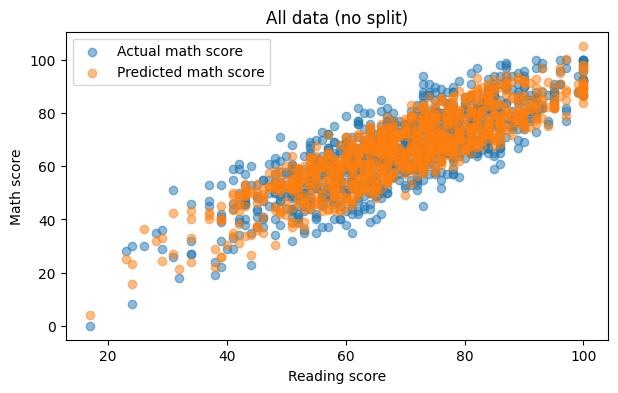

Training R^2: 0.8742732380399838
Test R^2: 0.8778243107659013


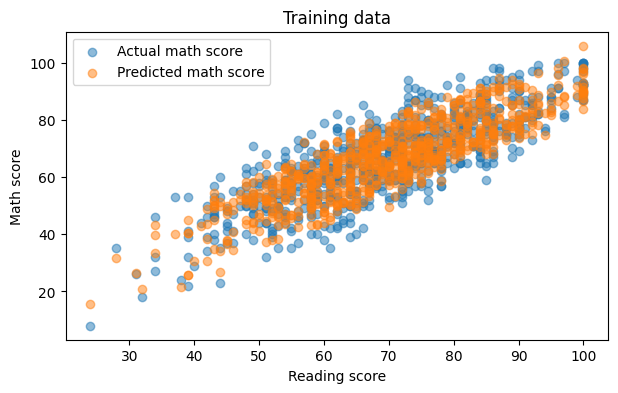

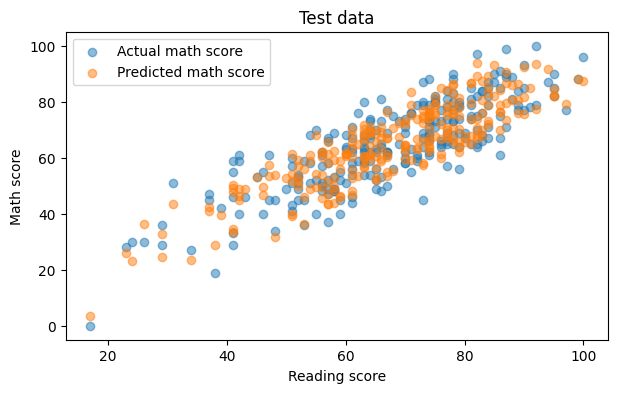

In [8]:
df = pd.read_csv("student_performance.csv")
df.columns = df.columns.str.strip().str.replace(" ", "_")
print(df.head())
print(df.dtypes)

# Encode all categorical columns as indicator variables, dropping the first value of each.
df_enc = pd.get_dummies(df, drop_first=True, dtype=float)

X_s = df_enc.drop("math_score", axis=1)
y_s = df_enc["math_score"]

def plot_vs_reading(reading, actual, predicted, title):
    """Reading score on the x-axis; actual and predicted math scores on the y-axis."""
    plt.figure(figsize=(7, 4))
    plt.scatter(reading, actual, alpha=0.5, label="Actual math score")
    plt.scatter(reading, predicted, alpha=0.5, label="Predicted math score")
    plt.xlabel("Reading score")
    plt.ylabel("Math score")
    plt.title(title)
    plt.legend()
    plt.show()

# 1. Fit using all the data
model_all = LinearRegression().fit(X_s, y_s)
pred_dummies = model_all.predict(X_s)
print("R^2 (all data):", model_all.score(X_s, y_s))
plot_vs_reading(X_s["reading_score"], y_s, pred_dummies, "All data (no split)")

# 2. Train/test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.25, random_state=42
)
model_split = LinearRegression().fit(Xs_train, ys_train)
print("Training R^2:", model_split.score(Xs_train, ys_train))
print("Test R^2:", model_split.score(Xs_test, ys_test))

plot_vs_reading(Xs_train["reading_score"], ys_train, model_split.predict(Xs_train), "Training data")
plot_vs_reading(Xs_test["reading_score"], ys_test, model_split.predict(Xs_test), "Test data")

## Question 7. Using `OneHotEncoder`

Repeat the above but this time use `sklearn.preprocessing.OneHotEncoder` to preprocess the data and fit a linear model. Compare the results.

R^2 (all data): 0.8767065867355993


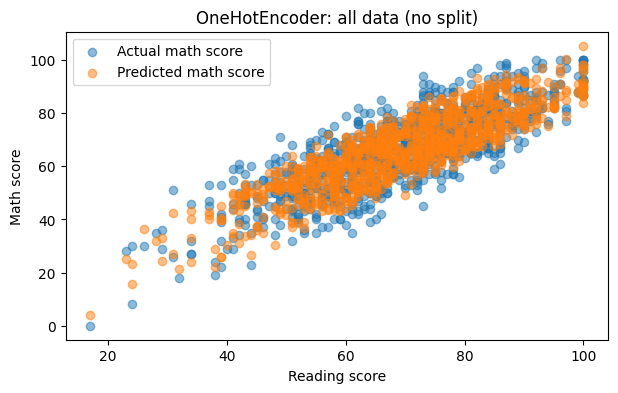

Training R^2: 0.8742732380399839
Test R^2: 0.8778243107659007


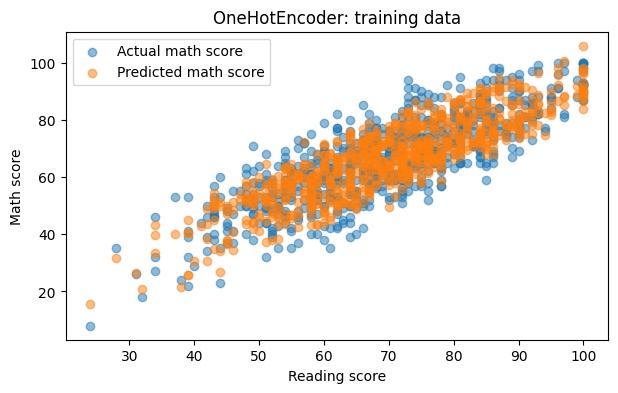

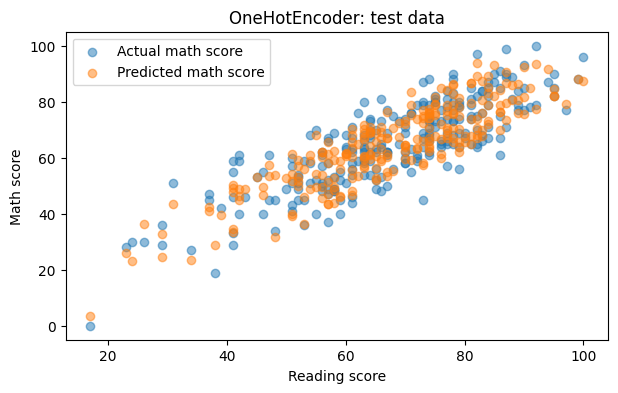

Max |difference| in predictions: 2.4158453015843406e-13
Same predictions: True


In [9]:
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = [c for c in df.columns if c not in cat_cols + ["math_score"]]

encoder = OneHotEncoder(drop="first", sparse_output=False)
cat_array = encoder.fit_transform(df[cat_cols])

X_o = pd.DataFrame(
    np.hstack([cat_array, df[num_cols].to_numpy()]),
    columns=list(encoder.get_feature_names_out(cat_cols)) + num_cols,
)
y_o = df["math_score"]

# All data
model_o = LinearRegression().fit(X_o, y_o)
pred_ohe = model_o.predict(X_o)
print("R^2 (all data):", model_o.score(X_o, y_o))
plot_vs_reading(X_o["reading_score"], y_o, pred_ohe, "OneHotEncoder: all data (no split)")

# Train/test split (same random_state, so the same rows as before)
Xo_train, Xo_test, yo_train, yo_test = train_test_split(X_o, y_o, test_size=0.25, random_state=42)
model_o_split = LinearRegression().fit(Xo_train, yo_train)
print("Training R^2:", model_o_split.score(Xo_train, yo_train))
print("Test R^2:", model_o_split.score(Xo_test, yo_test))
plot_vs_reading(Xo_train["reading_score"], yo_train, model_o_split.predict(Xo_train), "OneHotEncoder: training data")
plot_vs_reading(Xo_test["reading_score"], yo_test, model_o_split.predict(Xo_test), "OneHotEncoder: test data")

# Comparison with pd.get_dummies: both encodings drop the first category of each feature,
# so the models span the same space and the predictions should agree to rounding error.
print("Max |difference| in predictions:", np.abs(pred_ohe - pred_dummies).max())
print("Same predictions:", np.allclose(pred_ohe, pred_dummies))

# Conclusion: the two encodings give identical R^2 values and predictions. Both drop the first
# category of every feature, so they describe the same linear model; only the column order and
# names of the features differ.

## Question 8. Hyperparameters and the validation curve

Read the section on [hyperparameters and model validation](https://jakevdp.github.io/PythonDataScienceHandbook/05.03-hyperparameters-and-model-validation.html).  Consider the following function given there to make some data.

```python
import numpy as np

def make_data(N, err=1.0, rseed=1):
    # randomly sample the data
    rng = np.random.RandomState(rseed)
    X = rng.rand(N, 1) ** 2
    y = 10 - 1. / (X.ravel() + 0.1)
    if err > 0:
        y += err * rng.randn(N)
    return X, y
```

Use this function to make data for 40 points as done in the book. Then repeat the calculations done there to see what happens when you increase the order of the polynomial and plot the validation curve. Note that the import in the book `from sklearn.learning_curve import validation_curve` is out-of-date and should now be `from sklearn.model_selection import validation_curve`.

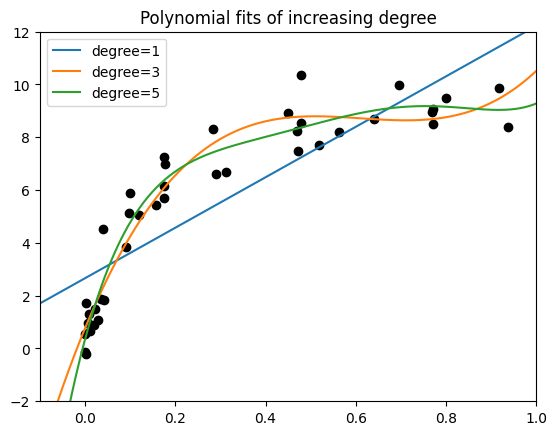

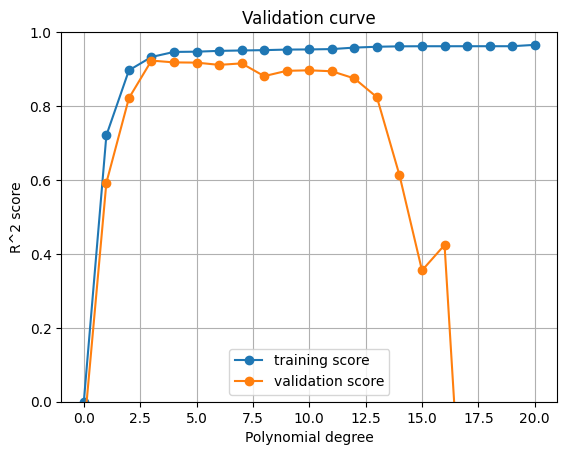

Best degree on validation score: 3


In [10]:
def make_data(N, err=1.0, rseed=1):
    # randomly sample the data
    rng = np.random.RandomState(rseed)
    X = rng.rand(N, 1) ** 2
    y = 10 - 1. / (X.ravel() + 0.1)
    if err > 0:
        y += err * rng.randn(N)
    return X, y

def PolynomialRegression(degree=2, **kwargs):
    return make_pipeline(PolynomialFeatures(degree), LinearRegression(**kwargs))

X8, y8 = make_data(40)

# Fits of increasing degree (as in the book)
X_test8 = np.linspace(-0.1, 1.1, 500)[:, None]
plt.scatter(X8.ravel(), y8, color="black")
for degree in [1, 3, 5]:
    y_fit = PolynomialRegression(degree).fit(X8, y8).predict(X_test8)
    plt.plot(X_test8.ravel(), y_fit, label=f"degree={degree}")
plt.xlim(-0.1, 1.0)
plt.ylim(-2, 12)
plt.legend(loc="best")
plt.title("Polynomial fits of increasing degree")
plt.show()

# Validation curve
degrees = np.arange(0, 21)
train_score, val_score = validation_curve(
    PolynomialRegression(), X8, y8,
    param_name="polynomialfeatures__degree", param_range=degrees, cv=7
)

plt.plot(degrees, np.median(train_score, axis=1), marker="o", label="training score")
plt.plot(degrees, np.median(val_score, axis=1), marker="o", label="validation score")
plt.ylim(0, 1)   # very negative validation scores at high degree would otherwise squash the plot
plt.xlabel("Polynomial degree")
plt.ylabel("R^2 score")
plt.title("Validation curve")
plt.legend(loc="best")
plt.grid()
plt.show()

print("Best degree on validation score:", degrees[np.argmax(np.median(val_score, axis=1))])

# Low degrees underfit (both scores low). The training score keeps creeping up with degree,
# but the validation score peaks around degree 3 and then falls: overfitting.

## Question 9. Validation curve for the pendulum data

Use the approach from the previous problem to look at our original pendulum data and see what happens with increasing degree of polynomials for this data. In particular plot the validation curve for this data as done in the previous problem.

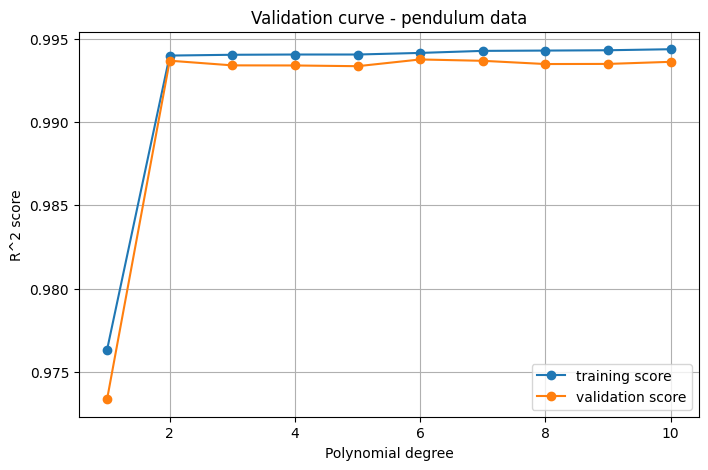

Best degree on validation score: 6


In [11]:
# Same set-up as Question 4: time period as the feature, length as the target.
# The data are sorted by length, so shuffle the folds; otherwise each fold is a contiguous
# block and the validation score mostly measures extrapolation.
degrees9 = np.arange(1, 11)
cv9 = KFold(n_splits=7, shuffle=True, random_state=0)

train_score9, val_score9 = validation_curve(
    PolynomialRegression(), X_t, y_l,
    param_name="polynomialfeatures__degree", param_range=degrees9, cv=cv9
)

plt.figure(figsize=(8, 5))
plt.plot(degrees9, np.median(train_score9, axis=1), marker="o", label="training score")
plt.plot(degrees9, np.median(val_score9, axis=1), marker="o", label="validation score")
plt.xlabel("Polynomial degree")
plt.ylabel("R^2 score")
plt.title("Validation curve - pendulum data")
plt.legend(loc="best")
plt.grid()
plt.show()

print("Best degree on validation score:", degrees9[np.argmax(np.median(val_score9, axis=1))])

# Degree 1 underfits slightly. From degree 2 on, both curves are flat to within about 0.001,
# so the "best" degree printed above is within noise: choose the simplest (degree 2).
# This agrees with t^2 = 4*pi^2 l / g, i.e. l is proportional to t^2. Unlike Question 8, the
# data are nearly noise-free and low-order, so there is no visible overfitting up to degree 10.

## Question 10. Making blobs

Look at the `sklearn.datasets.make_blobs` function from the scikit-learn documentation. Use this to make blobs with two and three centers each (see the `centers` keyword argument). Plot the centers for two and three blobs (in separate figures). Use about 50 points for each blob, so 100 for 2 centers and 150 for 3.  You can see examples of this in the [Naive Bayes section](https://jakevdp.github.io/PythonDataScienceHandbook/05.05-naive-bayes.html) of the data science handbook.

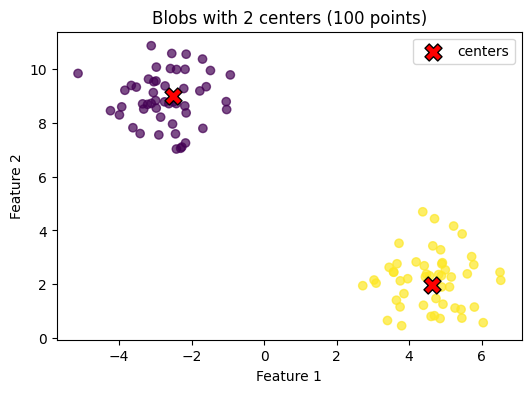

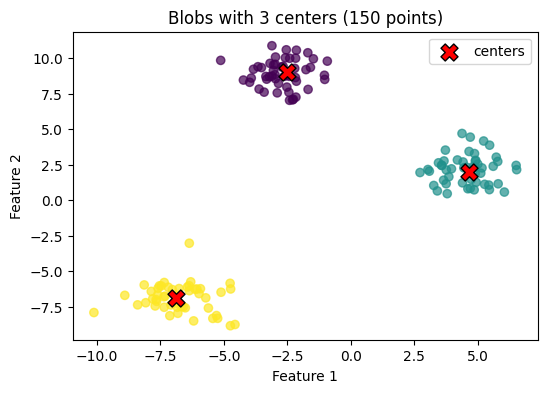

In [12]:
for n_centers in [2, 3]:
    Xb, yb, centers = make_blobs(
        n_samples=50 * n_centers,      # 50 points per blob
        centers=n_centers,
        random_state=42,
        return_centers=True,
    )
    plt.figure(figsize=(6, 4))
    plt.scatter(Xb[:, 0], Xb[:, 1], c=yb, alpha=0.7)
    plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=150, edgecolor="black", label="centers")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(f"Blobs with {n_centers} centers ({len(Xb)} points)")
    plt.legend()
    plt.show()

## Question 11. Gaussian Naive Bayes classification

Use `make_blobs` to create two clusters of points (say 200 points). Use `sklearn.naive_bayes.GaussianNB` to classify the points. Split the data into 80% for training and 20% for testing. After training compute the following for the **training and test data** separately (note that once trained, you can use `model.predict_proba` to get the probabilities for each class).  For example, you should compute the test accuracy and training accuracy and report both.

- a. Show a confusion matrix. Hint: `sklearn.metrics.confusion_matrix`

- b. Compute the accuracy, precision, recall, and f1 scores. Hint: see `sklearn.metrics`

- c. Compute the ROC/AUC using the `auc, roc_curve, RocCurveDisplay` from `sklearn.metrics`

TRAINING DATA
Confusion matrix:
 [[77  0]
 [ 0 83]]
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 score : 1.0
ROC AUC  : 1.0 

TEST DATA
Confusion matrix:
 [[23  0]
 [ 0 17]]
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 score : 1.0
ROC AUC  : 1.0 



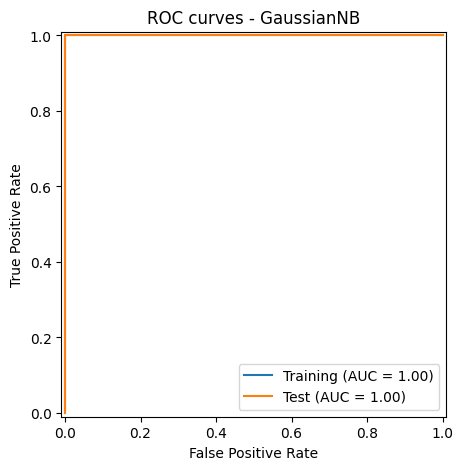

In [13]:
Xc, yc = make_blobs(n_samples=200, centers=2, random_state=42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.20, random_state=42)

nb = GaussianNB().fit(Xc_train, yc_train)

def evaluate(name, model, X, y):
    """Print confusion matrix and scores; return the ROC curve data."""
    y_pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    print(f"{name.upper()} DATA")
    print("Confusion matrix:\n", confusion_matrix(y, y_pred))
    print("Accuracy :", accuracy_score(y, y_pred))
    print("Precision:", precision_score(y, y_pred))
    print("Recall   :", recall_score(y, y_pred))
    print("F1 score :", f1_score(y, y_pred))
    fpr, tpr, _ = roc_curve(y, proba)
    roc_auc = auc(fpr, tpr)
    print("ROC AUC  :", roc_auc, "\n")
    return fpr, tpr, roc_auc

fpr_tr, tpr_tr, auc_tr = evaluate("training", nb, Xc_train, yc_train)
fpr_te, tpr_te, auc_te = evaluate("test", nb, Xc_test, yc_test)

fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay(fpr=fpr_tr, tpr=tpr_tr, roc_auc=auc_tr, name="Training").plot(ax=ax)
RocCurveDisplay(fpr=fpr_te, tpr=tpr_te, roc_auc=auc_te, name="Test").plot(ax=ax)
ax.set_title("ROC curves - GaussianNB")
plt.show()